# Employee Attrition Analysis (IBM HR dataset)

**Question:** Which employee characteristics are associated with leaving the company?

All the logic lives in the `hr_attrition` package. This notebook only calls those functions and presents the results.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from hr_attrition.data_loader import load_data, save_table, save_figure
from hr_attrition.cleaning import (
    count_missing_values,
    drop_constant_columns,
    encode_attrition,
    add_age_group,
)
from hr_attrition.analysis import attrition_rate_by, attrition_pivot, attrition_pivot
from hr_attrition.stats_tests import (
    income_statistics,
    chi_square_test,
    attrition_t_test,
)
from hr_attrition.visualization import (
    plot_attrition_rate,
    plot_attrition_heatmap,
    plot_income_by_attrition,
)

print("Setup OK. Project root:", ROOT_DIR)

Setup OK. Project root: /Users/sen/PythonProject/HR-analytics


## 1. Load and inspect the data

The dataset has one row per employee and a column `Attrition` (Yes = the employee left).

In [2]:
raw = load_data()
print("Shape", raw.shape)
raw.head()

Shape (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
missing = count_missing_values(raw)
print("Total missing", missing.sum())
raw["Attrition"].value_counts()

Total missing 0


Attrition
No     1233
Yes     237
Name: count, dtype: int64

**Observations:** 1470 employees and 35 columns, with no missing values. 237 employees (16.1%) left the company, so the two groups are unbalanced: in the analysis we compare the attrition **rates**, not counts.

## 2. Clean and prepare the data

Three steps: drop columns that have the same value for every employee, turn `Attrition` into a 0/1 flag, and group ages into bands.

In [4]:
df = drop_constant_columns(raw)
df = encode_attrition(df)
df = add_age_group(df)

dropped = sorted(set(raw.columns) - set(df.columns))
print("Dropped columns:", dropped)
print("Shape after cleaning:", df.shape)

overall_rate = df["AttritionFlag"].mean()
print(f"Overall attrition rate: {overall_rate:.1%}")

df["AgeGroup"].value_counts().sort_index()

Dropped columns: ['EmployeeCount', 'Over18', 'StandardHours']
Shape after cleaning: (1470, 34)
Overall attrition rate: 16.1%


AgeGroup
18-29    326
30-39    622
40-49    349
50-60    173
Name: count, dtype: int64

**Observations:** Three constant columns were dropped because a column with the same value for everyone cannot explain differences between employees. The largest age group is 30-39 (622 employees).

## 3. Attrition rate by group

For eaach factor we compare the share of employees who left in each group. The dashed line is the company average.

,OverTime,employees,leavers,attrition_rate
1,Yes,416,127,0.305288
0,No,1054,110,0.104364


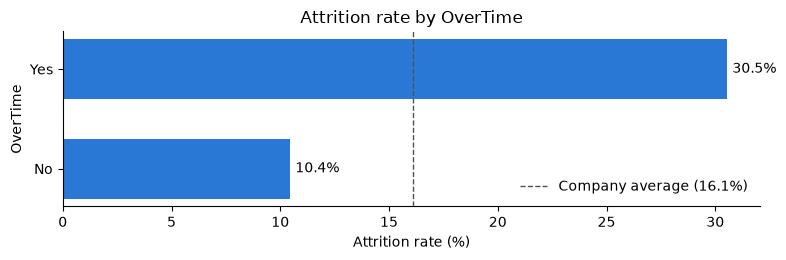

In [5]:
overtime = attrition_rate_by(df, "OverTime")
fig = plot_attrition_rate(overtime, "OverTime", overall_rate)
save_figure(fig, "attrition_by_overtime.png")
overtime

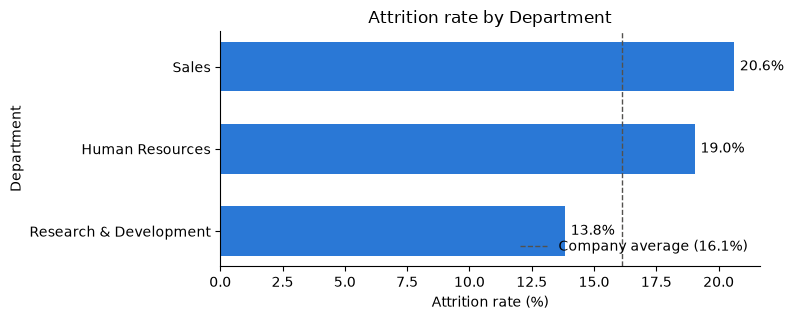

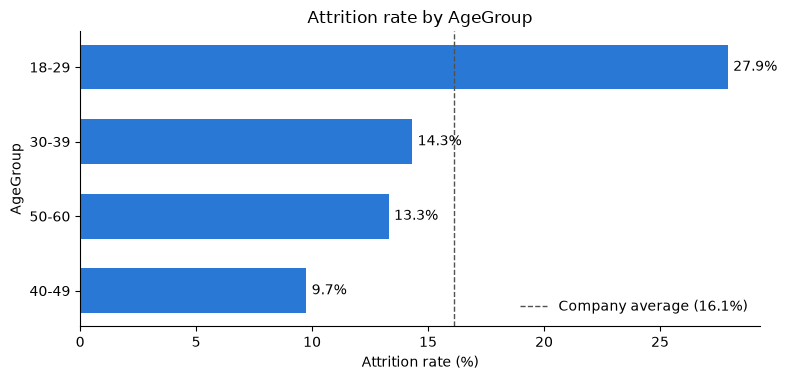

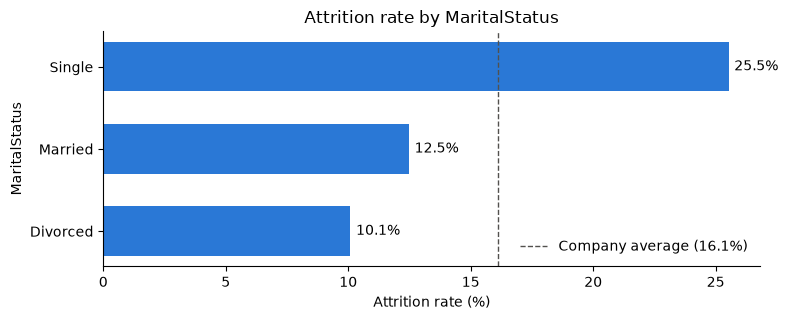

In [6]:
for column in ["Department", "AgeGroup", "MaritalStatus"]:
    summary = attrition_rate_by(df, column)
    fig = plot_attrition_rate(summary, column, overall_rate)
    save_figure(fig, f"attrition_by_{column.lower()}.png")

**Observations:** Employees who work overtime leave about three times as often as those who do not (30.5% vs 10.4%). Attrition  is also above average in Sales, among employees aged 18-29 and among single employees. These are differences in rates; Section 5 tests whether they are statistically significant.

## 4. Two factors combined

Does overtime affect every age group in the same way? The heatmap shows the attrition rate for each combination of age group and overtime.

OverTime,No,Yes
AgeGroup,,
18-29,0.177,0.532
30-39,0.094,0.282
40-49,0.065,0.176
50-60,0.086,0.228


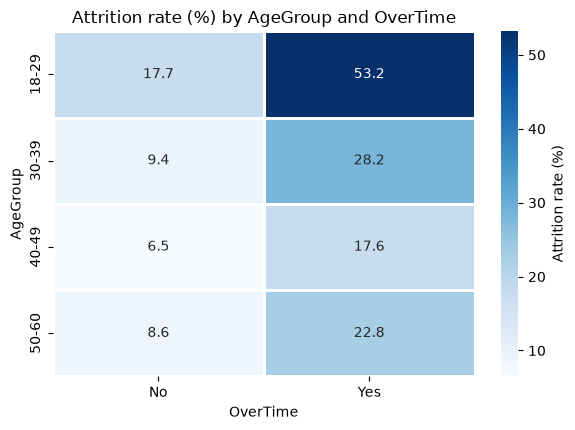

In [7]:
age_overtime = attrition_pivot(df, "AgeGroup", "OverTime")
fig = plot_attrition_heatmap(age_overtime)
save_figure(fig, "heatmap_age_overtime.png")
age_overtime.round(3)

**Observations:** In every age group, employees who work overtime
leave more often. The effect is strongest for young employees: 53.2%
of employees aged 18-29 who work overtime left, more than three times
the company average. HR could focus retention actions on this group.

## 5. Statistical tests

Are the differences above larger than what chance alone would produce?
We use a significance level of 0.05.

- **Chi-square test of independence** for categorical factors.
- **Welch t-test** for monthly income.

In [8]:
factors = ["OverTime", "Department", "AgeGroup", "MaritalStatus", "Gender"]

chi_results = []
for column in factors:
    chi_results.append(chi_square_test(df, column))

chi_table = pd.DataFrame(chi_results)
save_table(chi_table, "chi_square_results.csv")
chi_table

,column,chi2,dof,p_value,significant
0,OverTime,87.564294,1,8.158424e-21,True
1,Department,10.796007,2,4.525607e-03,True
2,AgeGroup,46.560924,3,4.309418e-10,True
3,MaritalStatus,46.163677,2,9.455511e-11,True
4,Gender,1.116967,1,2.905724e-01,False


{'column': 'MonthlyIncome', 'mean_leavers': 4787.0928270042195, 'mean_stayers': 6832.739659367397, 't_statistic': -7.482621586644742, 'p_value': 4.433588628286069e-13, 'significant': True}


,Attrition,employees,mean,std,p25,median,p75
0,No,1233,6833.0,4818.0,3211.0,5204.0,8834.0
1,Yes,237,4787.0,3640.0,2373.0,3202.0,5916.0


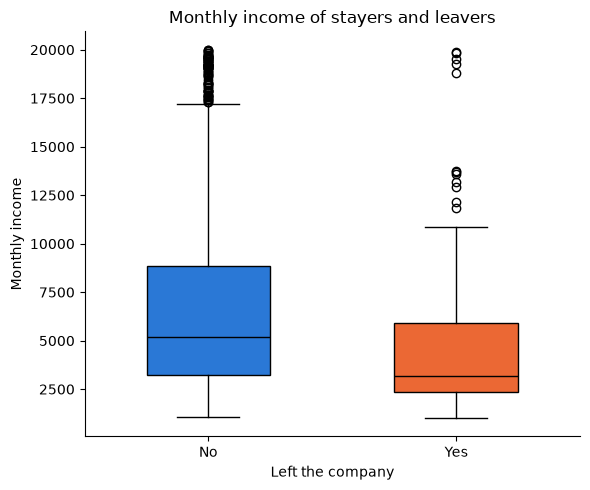

In [9]:
t_result = attrition_t_test(df)
print(t_result)

fig = plot_income_by_attrition(df)
save_figure(fig, "income_by_attrition.png")

income_statistics(df).round(0)

**Observations:** Overtime, Department, Age group and Marital status
are significantly associated with attrition (p < 0.05). With a
stricter threshold for five tests (0.05 / 5 = 0.01) the conclusion does
not change. Gender is not significant: we found no evidence of a
difference, which is not the same as proving there is none.
Leavers earn less (median monthly income 3,202 vs 5,204; Welch t-test,
p < 0.001). These are associations, not causes.

## 6. Conclusions and limitations

**Main findings**

1. Overtime is the factor most strongly associated with attrition:
   30.5% of employees who work overtime left, against 10.4% of the others.
2. Young employees who work overtime are the highest-risk group (53.2%).
3. Attrition is also higher in Sales, among single employees and among
   lower-paid employees.
4. Gender shows no significant association.

**What HR could do**

- Monitor overtime and limit it, especially for employees under 30.
- Review pay and career paths for the groups with the highest attrition.

**Limitations**

- These are associations, not causes. Factors may overlap: for example,
  younger employees also tend to earn less, so the age and income
  effects cannot be separated here.
- The dataset is fictional (created by IBM data scientists), so the
  results may not apply to a real company.
- It is a single snapshot: we do not know when or why people left.
- Each factor was tested on its own. A model that considers all factors
  together, such as logistic regression, would be a natural next step.